# Grupo 17:

Alicia Mei García Morín (100498828)

Ana Grima Vázquez de Prada (100495785)

El objetivo de esta práctica es identificar tipos de estrellas utilizando técnicas de aprendizaje no supervisado.

En este notebook se realiza el preprocesado de los datos, la reducción de dimensionalidad con PCA, la aplicación y comparación de distintos algoritmos de clustering, y la interpretación de los grupos obtenidos.

# 1. Carga de datos

En esta sección se cargan los datos que se utilizarán a lo largo de la práctica.



In [45]:
import pandas as pd
import numpy as np

SEED = 100498828
SEED_2 = 100498829

df = pd.read_csv("stars_data.csv")


# 2. EDA


## 2.1. Dimensiones del dataset


En esta sección se realiza un análisis exploratorio básico del dataset con el objetivo de entender su estructura y preparar el posterior preprocesamiento.

In [46]:
print("Dimensiones del dataset:", df.shape)
df.head()

Dimensiones del dataset: (240, 6)


,Temperature,L,R,A_M,Color,Spectral_Class
0,3068,0.002400,0.1700,16.12,Red,M
1,3042,0.000500,0.1542,16.60,Red,M
2,2600,0.000300,0.1020,18.70,Red,M
3,2800,0.000200,0.1600,16.65,Red,M
4,1939,0.000138,0.1030,20.06,Red,M


El dataset contiene:
- 240 instancias (filas) = número de estrellas
- 6 atributos (columnas) = número de atributos

In [47]:
df.dtypes


,0
Temperature,int64
L,float64
R,float64
A_M,float64
Color,object
Spectral_Class,object


In [48]:
categorical_columns = df.select_dtypes(include=["object"]).columns
numerical_columns   = df.select_dtypes(include=["int64","float64"]).columns

print("Categóricas:", list(categorical_columns))
print("Numéricas:", list(numerical_columns))

Categóricas: ['Color', 'Spectral_Class']
Numéricas: ['Temperature', 'L', 'R', 'A_M']


Se identifican 2 variables categóricas (de tipo objeto): `Color` y `Spectral_Class`

Y 4 variables numéricas (aquellas de tipo entero o flotante): `Temperature`, `L`, `R` y `A_M`.

El problema planteado corresponde a un problema de aprendizaje automático no supervisado (no hay vble objetivo), concretamente de clustering. El objetivo es agrupar las estrellas en función de sus características físicas y espectrales, identificando posibles grupos naturales en los datos.

## 2.2. Cardinalidad de variables categóricas

In [49]:
categorical_columns = df.select_dtypes(include=["object"]).columns
cardinality = df[categorical_columns].nunique()
cardinality

,0
Color,17
Spectral_Class,7


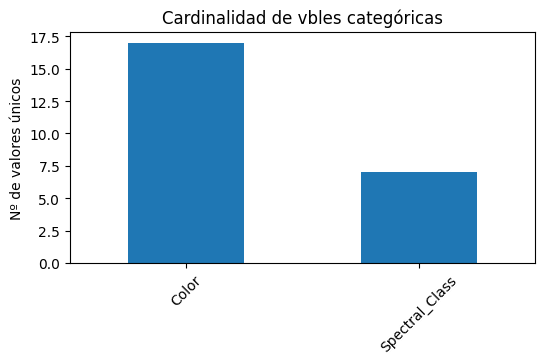

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,3))
cardinality.plot(kind="bar")
plt.title("Cardinalidad de vbles categóricas")
plt.ylabel("Nº de valores únicos")
plt.xticks(rotation=45)
plt.show()

Se observa que la variable `Color` presenta una mayor cardinalidad que `Spectral_Class`, ya que contiene un mayor número de valores distintos.

No obstante, esta cardinalidad puede considerarse moderada y manejable en el contexto del análisis.

Se normalizarán las categorías de la variable `Color` para unificar denominaciones equivalentes (por ejemplo, distintas formas de escribir un mismo color), y se hará una codificación ordinal tanto de `Color` como de `Spectral_Class`, teniendo en cuenta que ambas variables están relacionadas con la energía y temperatura de las estrellas.

## 2.3. Valores ausentes

In [51]:
print("How many missing values per attribute:")
print("======================================")
print(df.isnull().sum())

How many missing values per attribute:
Temperature       0
L                 0
R                 0
A_M               0
Color             0
Spectral_Class    0
dtype: int64


Observamos que ninguna variable presenta valores ausentes.

## 2.4 Columnas constantes o tipo ID

In [52]:
constant_cols = [col for col in df.columns if df[col].nunique() == 1]
print("Columnas constantes:", constant_cols)

id_cols = [col for col in df.columns if df[col].nunique() == len(df)]
print("Columnas tipo ID:", id_cols)

Columnas constantes: []
Columnas tipo ID: []


No se observan columnas constantes o columnas de ID.

## 2.5. Análisis de las variables numéricas

In [53]:
df[numerical_columns].describe()

,Temperature,L,R,A_M
count,240.000000,240.000000,240.000000,240.000000
mean,10497.462500,107188.361635,237.157781,4.382396
std,9552.425037,179432.244940,517.155763,10.532512
min,1939.000000,0.000080,0.008400,-11.920000
25%,3344.250000,0.000865,0.102750,-6.232500
50%,5776.000000,0.070500,0.762500,8.313000
75%,15055.500000,198050.000000,42.750000,13.697500
max,40000.000000,849420.000000,1948.500000,20.060000


Los estadísticos descriptivos muestran de nuevo que no existen valores faltantes en las variables numéricas.

Se observa además que las variables presentan escalas y rangos muy diferentes entre sí, lo que hace necesario aplicar un proceso de escalado antes de utilizar PCA y los algoritmos de clustering.

# 3. Preprocesamiento


## 3.1. Codificación de variables categóricas

El dataset contiene dos variables categóricas: `Color` y `Spectral_Class`.

La variable `Spectral_Class` tiene un orden físico natural, ya que la clasificación espectral ordena las estrellas desde las más calientes hasta las más frías: O, B, A, F, G, K, M. Por ello lo codificamos de forma ordinal.

La variable `Color` también está relacionada con la energía y temperatura de la estrella. Sin embargo, en el dataset aparecen distintas formas de escribir colores equivalentes, por lo que primero se normalizan estas categorías antes de codificarlas.

In [54]:
df_processed = df.copy()

df_processed["Color"] = (
    df_processed["Color"]
    .str.strip()
    .str.lower()
    .str.replace("-", " ", regex=False)
)

color_mapping = {
    "blue white": "blue white",
    "bluewhite": "blue white",
    "white": "white",
    "whitish": "white",
    "yellowish white": "yellow white",
    "yellow white": "yellow white",
    "white yellow": "yellow white",
    "yellowish": "yellow",
    "pale yellow orange": "orange",
    "orange red": "red",
    "red": "red",
    "orange": "orange",
    "blue": "blue"
}

df_processed["Color"] = df_processed["Color"].replace(color_mapping)

spectral_order = {
    "O": 0,
    "B": 1,
    "A": 2,
    "F": 3,
    "G": 4,
    "K": 5,
    "M": 6
}

color_order = {
    "blue": 0,
    "blue white": 1,
    "white": 2,
    "yellow white": 3,
    "yellow": 4,
    "orange": 5,
    "red": 6
}

df_processed["Spectral_Class_encoded"] = df_processed["Spectral_Class"].map(spectral_order)
df_processed["Color_encoded"] = df_processed["Color"].map(color_order)

df_processed.head()

,Temperature,L,R,A_M,Color,Spectral_Class,Spectral_Class_encoded,Color_encoded
0,3068,0.002400,0.1700,16.12,red,M,6,6
1,3042,0.000500,0.1542,16.60,red,M,6,6
2,2600,0.000300,0.1020,18.70,red,M,6,6
3,2800,0.000200,0.1600,16.65,red,M,6,6
4,1939,0.000138,0.1030,20.06,red,M,6,6


# 3.2. Selección de variables

Una vez codificadas las variables categóricas, vamos a construir la matriz de entrada que se utilizará para el análisis no supervisado.

Esta matriz incluye tanto las variables numéricas originales como las variables categóricas codificadas ordinalmente.

In [55]:
X = df_processed[
    [
        "Temperature",
        "L",
        "R",
        "A_M",
        "Color_encoded",
        "Spectral_Class_encoded"
    ]
]

X.head()

,Temperature,L,R,A_M,Color_encoded,Spectral_Class_encoded
0,3068,0.002400,0.1700,16.12,6,6
1,3042,0.000500,0.1542,16.60,6,6
2,2600,0.000300,0.1020,18.70,6,6
3,2800,0.000200,0.1600,16.65,6,6
4,1939,0.000138,0.1030,20.06,6,6


## 3.3. Escalado de variables

Antes de aplicar PCA y los algoritmos de clustering, escalamos las variables mediante `StandardScaler`, ya que estos métodos son sensibles a las diferencias de escala entre variables.

In [56]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

## 3.4. Reducción de dimensionalidad mediante PCA

Para facilitar la visualización de los datos y la tarea de clustering, se aplica PCA con dos componentes principales, tal y como indica el enunciado.

A partir de este punto, los algoritmos de clustering se aplicarán directamente sobre estas dos componentes principales.

In [57]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED)

X_pca = pca.fit_transform(X_scaled)

X_pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

X_pca_df.head()

,PC1,PC2
0,2.062933,-0.155353
1,2.082440,-0.173248
2,2.183931,-0.244008
3,2.096245,-0.169631
4,2.268088,-0.281221


In [58]:
explained_variance = pca.explained_variance_ratio_

print("Varianza explicada PC1:", round(explained_variance[0], 3))
print("Varianza explicada PC2:", round(explained_variance[1], 3))
print("Varianza total:", round(explained_variance.sum(), 3))

Varianza explicada PC1: 0.558
Varianza explicada PC2: 0.296
Varianza total: 0.853


Las dos primeras componentes principales explican una proporción significativa de la varianza total del dataset, lo que justifica su uso para la visualización y el análisis mediante clustering.

A continuación, se representa gráficamente la proyección de las estrellas en las dos primeras componentes principales. Esta visualización permite observar posibles agrupaciones naturales antes de aplicar los algoritmos de clustering.

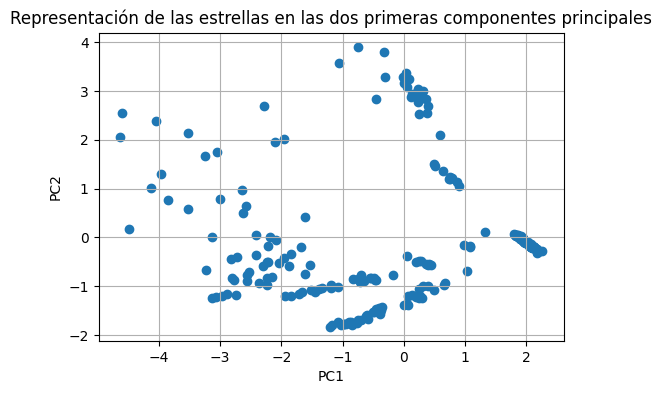

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

plt.scatter(
    X_pca_df["PC1"],
    X_pca_df["PC2"]
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title("Representación de las estrellas en las dos primeras componentes principales")

plt.grid(True)

plt.show()

Esto sugiere que los algoritmos de clustering pueden identificar grupos de estrellas con características similares. Por tanto, se procede a aplicar los métodos de clustering sobre estas dos componentes principales.

# 4. K-Means

## 4.1. Selección del número de clusters




Se aplica el algoritmo K-Means sobre las dos componentes principales obtenidas mediante PCA.

Para seleccionar el número adecuado de clusters se utilizan dos métricas:

- Inercia (Elbow method)
- Silhouette score

Estas métricas permiten evaluar la calidad de los agrupamientos obtenidos y seleccionar el número de clusters más adecuado.

In [60]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette_scores = []

K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=10
    )

    labels = kmeans.fit_predict(X_pca_df)

    inertia.append(kmeans.inertia_)

    silhouette_scores.append(
        silhouette_score(X_pca_df, labels)
    )

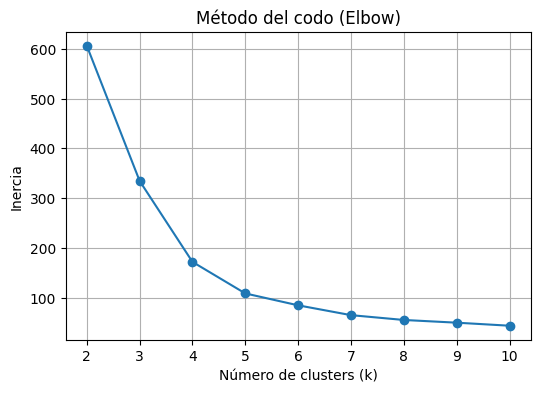

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

plt.plot(
    K_range,
    inertia,
    marker="o"
)

plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")

plt.title("Método del codo (Elbow)")

plt.grid(True)

plt.show()

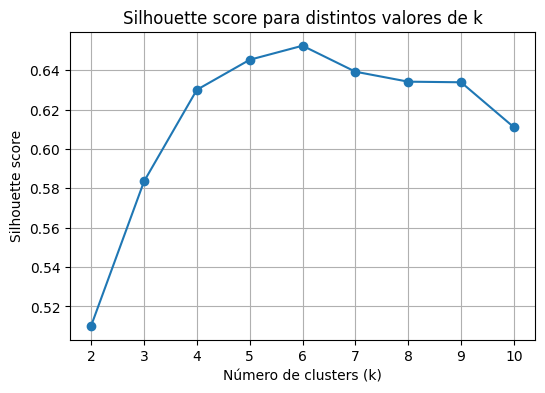

In [64]:
plt.figure(figsize=(6, 4))

plt.plot(
    K_range,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette score")

plt.title("Silhouette score para distintos valores de k")

plt.grid(True)

plt.show()

A partir del gráfico del método del codo (Elbow), se observa una reducción significativa de la inercia al aumentar el número de clusters desde k=2 hasta k=4 o k=5. A partir de ese punto, la disminución de la inercia se vuelve más gradual, lo que sugiere la presencia de un posible "codo" en torno a esos valores.

Por otro lado, el análisis del silhouette score muestra que el valor máximo se alcanza para k=6, lo que indica que esta configuración proporciona la mejor separación y cohesión entre los clusters en comparación con el resto de valores evaluados.

Teniendo en cuenta ambas métricas, se selecciona **k=6** como número de clusters para aplicar el algoritmo **K-Means**, ya que combina una buena reducción de la inercia con el mayor valor de silhouette score, lo que sugiere una estructura de agrupamiento adecuada en los datos.

## 4.2. Aplicación final de K-Means

In [65]:
kmeans = KMeans(
    n_clusters=6,
    random_state=SEED,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_pca_df)

X_pca_df["cluster_kmeans"] = kmeans_labels

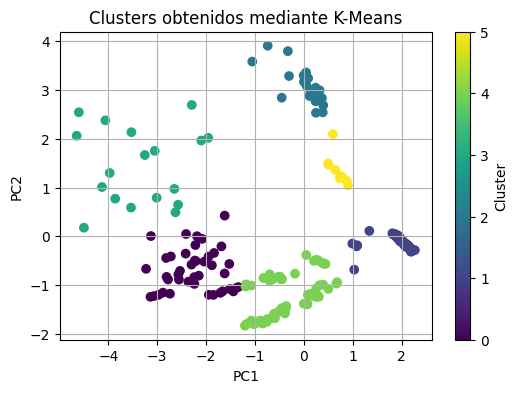

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.scatter(
    X_pca_df["PC1"],
    X_pca_df["PC2"],
    c=X_pca_df["cluster_kmeans"],
    cmap="viridis"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title("Clusters obtenidos mediante K-Means")

plt.colorbar(label="Cluster")

plt.grid(True)

plt.show()

La representación gráfica de los datos en el espacio de las dos primeras componentes principales muestra que el algoritmo K-Means ha identificado **seis grupos diferenciados de estrellas**.

Se observa que los clusters están relativamente bien separados entre sí, lo que indica que el número de clusters seleccionado (k=6) permite capturar adecuadamente la estructura de los datos. Cada color representa un grupo de estrellas con características similares en términos de temperatura, luminosidad, radio y magnitud absoluta.

Estos resultados sugieren que el algoritmo K-Means es capaz de segmentar las estrellas en grupos coherentes, lo que facilita la posterior interpretación y caracterización de los distintos tipos de estrellas.

# 5. Hierarchical Clustering

# 6. Dendrogramas (DBSCAN)


# . Reducción de dimensionalidad (PCA)


# . Clustering tras PCA


# . Comparación de resultados


# . Conclusiones